# 05 - Simplified MedViT on PneumoniaMNIST

Final architecture in the comparison. Implemented from scratch in `src/models.py` (`MedViTSmall`), as a hierarchical hybrid of convolutional (ECB) and transformer (LTB) stages, in the spirit of MedViT (Manzari et al., 2023):
- **Stage 1-2 (ECB, convolutional):** depthwise + pointwise convolutions, cheap and local, while the feature map is still spatially large (28x28, then 14x14).
- **Stage 3 (LTB, hybrid transformer):** at 7x7 (49 tokens), combines a **global** self-attention branch (reusing the same attention built for the ViT notebook) with a **local** convolutional branch, merged together — this is MedViT's central idea.

See the `MedViTSmall`, `ECBBlock`, `HybridAttention` and `LocalFeedForward` docstrings in `src/models.py` for exactly which parts are simplified relative to the original paper.

**Hypothesis to test:** does combining convolutional locality with global attention let MedViT recover the specificity that the pure ViT lost, while keeping (or improving) its AUC? This is the central question of the whole project.

In [1]:
import sys
sys.path.append("..")

import torch

from src.data import get_dataloaders
from src.models import build_model
from src.train import train_model, evaluate_on_test
from src.utils import set_seed, get_device

set_seed(42)
device = get_device()
print("Using device:", device)


Using device: cuda


## 1. Load data

In [2]:
FLAG = "pneumoniamnist"
SIZE = 28
BATCH_SIZE = 128

loaders, spec = get_dataloaders(FLAG, size=SIZE, batch_size=BATCH_SIZE,
                                root="../data", use_train_stats=True)
print(spec)

DatasetSpec(flag='pneumoniamnist', task='binary-class', n_channels=1, n_classes=2, labels={'0': 'normal', '1': 'pneumonia'})


## 2. Build the simplified MedViT

In [3]:
model = build_model("medvit", n_channels=spec.n_channels, n_classes=spec.n_classes)
n_params = sum(p.numel() for p in model.parameters())
print(f"MedViT (simplified) has {n_params:,} parameters")
# For reference: SimpleCNN ~23.6k | ViT ~138k | MedViT ~447k | ResNet-18 ~11.17M

MedViT (simplified) has 446,754 parameters


## 3. Train

In [4]:
history = train_model(
    model, loaders, spec, device,
    epochs=15,
    lr=1e-3,
    out_dir="../results",
    run_name="medvit_pneumoniamnist",
    monitor="auc",
    early_stopping_patience=5,
)

medvit_pneumoniamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[medvit_pneumoniamnist] epoch 01 | train loss 0.2210 | val auc 0.9777 (best)
[medvit_pneumoniamnist] epoch 02 | train loss 0.1259 | val auc 0.9914 (best)
[medvit_pneumoniamnist] epoch 03 | train loss 0.0867 | val auc 0.9933 (best)
[medvit_pneumoniamnist] epoch 04 | train loss 0.0716 | val auc 0.9958 (best)
[medvit_pneumoniamnist] epoch 05 | train loss 0.0490 | val auc 0.9913
[medvit_pneumoniamnist] epoch 06 | train loss 0.0416 | val auc 0.9900
[medvit_pneumoniamnist] epoch 07 | train loss 0.0271 | val auc 0.9904
[medvit_pneumoniamnist] epoch 08 | train loss 0.0261 | val auc 0.9892
[medvit_pneumoniamnist] epoch 09 | train loss 0.0170 | val auc 0.9874
[medvit_pneumoniamnist] no improvement in 5 epochs, stopping early at epoch 9.
[medvit_pneumoniamnist] loaded best checkpoint from epoch 4 (val auc=0.9958)


## 4. Plot training curves

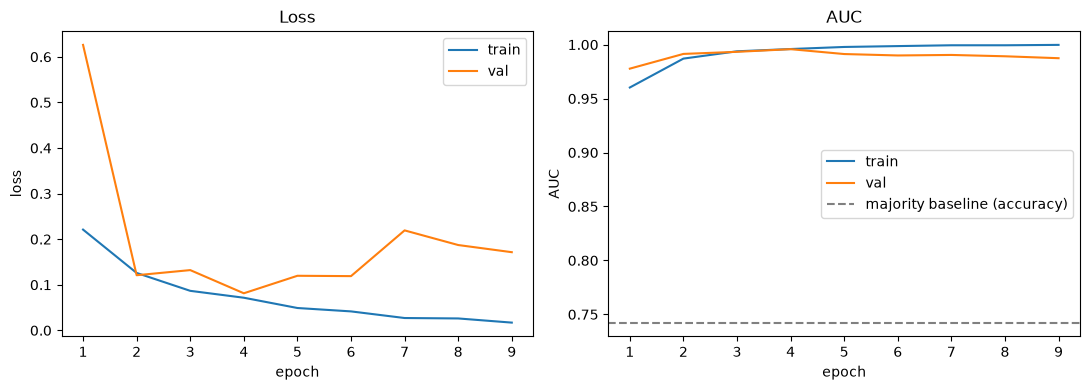

In [5]:
import matplotlib.pyplot as plt

train_hist, val_hist = history["train"], history["val"]
epochs_ran = [h["epoch"] for h in train_hist]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs_ran, [h["loss"] for h in train_hist], label="train")
axes[0].plot(epochs_ran, [h["loss"] for h in val_hist], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
axes[0].set_title("Loss")

axes[1].plot(epochs_ran, [h["auc"] for h in train_hist], label="train")
axes[1].plot(epochs_ran, [h["auc"] for h in val_hist], label="val")
axes[1].axhline(val_hist[0]["majority_baseline_accuracy"], color="gray",
                linestyle="--", label="majority baseline (accuracy)")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("AUC"); axes[1].legend()
axes[1].set_title("AUC")
plt.tight_layout(); plt.show()

## 5. Final evaluation on the test split

In [6]:
test_result = evaluate_on_test(model, loaders, spec, device,
                               out_dir="../results",
                               run_name="medvit_pneumoniamnist")
test_result

[medvit_pneumoniamnist] TEST metrics: EvalResult(task=binary-class, accuracy=0.8205, balanced_accuracy=0.7615, auc=0.9629, f1=0.8742, sensitivity=0.9974, specificity=0.5256, majority_baseline_accuracy=0.6250)


EvalResult(task=binary-class, accuracy=0.8205, balanced_accuracy=0.7615, auc=0.9629, f1=0.8742, sensitivity=0.9974, specificity=0.5256, majority_baseline_accuracy=0.6250)

## 6. Confusion matrix

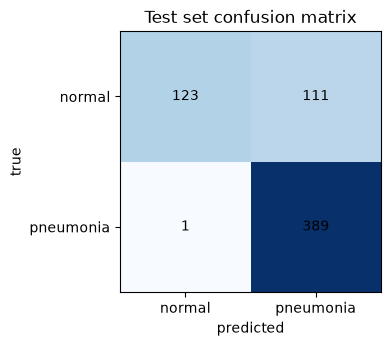

In [7]:
cm = test_result.confusion
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")
labels = [spec.labels[str(c)] for c in range(spec.n_classes)]
ax.set_xticks(range(spec.n_classes)); ax.set_xticklabels(labels)
ax.set_yticks(range(spec.n_classes)); ax.set_yticklabels(labels)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Test set confusion matrix")
plt.tight_layout(); plt.show()

## 7. Full comparison: all four architectures

The key table for this project's research question.

In [8]:
import json
import pandas as pd

results_files = {
    "SimpleCNN": "simple_cnn_pneumoniamnist_test_metrics.json",
    "ResNet-18": "resnet18_pneumoniamnist_test_metrics.json",
    "ViT": "vit_pneumoniamnist_test_metrics.json",
}
rows = []
for model_name, fname in results_files.items():
    with open(f"../results/{fname}") as f:
        rows.append({"model": model_name, **json.load(f)})
rows.append({"model": "MedViT (simplified)", **test_result.as_dict()})

comparison = pd.DataFrame(rows).set_index("model")
comparison = comparison.loc[["SimpleCNN", "ResNet-18", "ViT", "MedViT (simplified)"]]
comparison[["accuracy", "balanced_accuracy", "auc", "f1", "sensitivity", "specificity"]]

,accuracy,balanced_accuracy,auc,f1,sensitivity,specificity
model,,,,,,
SimpleCNN,0.865385,0.824786,0.968080,0.901639,0.987179,0.662393
ResNet-18,0.875000,0.839316,0.953408,0.907583,0.982051,0.696581
ViT,0.812500,0.750000,0.956728,0.869565,1.000000,0.500000
MedViT (simplified),0.820513,0.761538,0.962875,0.874157,0.997436,0.525641


## 8. Parameter count vs. performance

A quick view of the cost/benefit trade-off across all four models.

In [9]:
param_counts = {
    "SimpleCNN": 23_650,
    "ResNet-18": 11_168_706,
    "ViT": 138_498,
    "MedViT (simplified)": sum(p.numel() for p in model.parameters()),
}
summary = comparison.copy()
summary["n_params"] = [param_counts[m] for m in summary.index]
summary[["n_params", "auc", "balanced_accuracy", "specificity"]]

,n_params,auc,balanced_accuracy,specificity
model,,,,
SimpleCNN,23650,0.968080,0.824786,0.662393
ResNet-18,11168706,0.953408,0.839316,0.696581
ViT,138498,0.956728,0.750000,0.500000
MedViT (simplified),446754,0.962875,0.761538,0.525641


## 9. Observations

MedViT (simplified) achieves the best AUC among the three non-CNN-baseline
models (0.9629, vs 0.9567 for ViT and 0.9534 for ResNet-18), but still trails
SimpleCNN's 0.9681. Its specificity (0.5256) is only marginally better than
ViT's (0.5000) and remains far below both CNNs (0.66-0.70), so the central
hypothesis — that combining global attention with convolutional locality
would recover CNN-level specificity — is only weakly supported by this result.

A likely explanation lies in this implementation's design: locality is
concentrated in the early convolutional stages (ECB), while the final stage
tokenizes features and ends with simple mean pooling, which may wash out the
fine-grained spatial information needed to resolve ambiguous (often normal)
cases. The real MedViT interleaves convolutional and hybrid blocks more
thoroughly throughout the network, rather than strictly separating "early
conv, late attention" as done here.

Training also converged notably faster than the other three models: the best
checkpoint was reached at epoch 4 (val AUC 0.9958), versus epochs 9-13 for
the others, with early stopping triggered at epoch 9. This suggests MedViT
found a shortcut toward the majority-class bias relatively early, rather than
needing more training to refine the decision boundary.

Overall conclusion for this single-subset phase: increased model complexity
(ViT, ResNet-18, MedViT) did not translate into clearly better performance
than the much smaller SimpleCNN baseline on PneumoniaMNIST. MedViT's hybrid
design improved AUC over the pure ViT, supporting the value of combining
local and global signal for overall ranking ability, but did not solve the
class-imbalance-driven specificity problem — a nuance worth testing further
on DermaMNIST and OrganAMNIST, where class imbalance and data volume differ.